# Monthly crime and London house sales: merge, measurement audit and exposure models

This standalone notebook merges `MPS LSOA Level Crime (Historical).csv` with the original `land_registry_crime.dta`. Use the **eda** kernel and run from the project folder. It preserves every original transaction in the exported merged data and uses separately documented samples for regressions. Original files and notebooks are unchanged.

Questions: Does the monthly source improve the supplied crime measures? Which transactions can be assigned crime recorded during the twelve completed months before sale? How do annual and prior crime associations compare after neighbourhood and time controls?

Recorded crime, public knowledge of crime and perceived risk differ. These estimates are associations; neither historical exposure nor fixed effects establishes causality.

In [ ]:
from pathlib import Path
import hashlib, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

ROOT=Path.cwd()
DATA=ROOT/'project_data/land_registry_crime.dta'
MPS=ROOT/'project_data/MPS LSOA Level Crime (Historical).csv'
OUT=ROOT/'monthly_crime_merge_outputs'
OUT.mkdir(exist_ok=True)
df=pd.read_stata(DATA,convert_categoricals=False)
df['transaction_id']=np.arange(len(df))  # row identity; not a repeat-sales property ID
raw=pd.read_csv(MPS,encoding='utf-8-sig')
raw.columns=raw.columns.str.strip()
def table(x,name):
    display(x)
    x.to_csv(OUT/(name+'.csv'))
table(pd.DataFrame({'path':[str(DATA),str(MPS)],
                    'sha256':[hashlib.sha256(p.read_bytes()).hexdigest() for p in [DATA,MPS]]}), 'input_provenance')
print('Transactions:',len(df),'MPS category rows:',len(raw))
print('Transaction dates:',df.transactiondates.min(),df.transactiondates.max())

Transactions: 549813 MPS category rows: 112977
Transaction dates: 2010-01-01 00:00:00 2015-07-30 00:00:00


,path,sha256
0,C:\Users\rachm\OneDrive - Nanyang Technologica...,358171a5f337d5ad53e665552b382096cdc7f566ae4ff8...
1,C:\Users\rachm\OneDrive - Nanyang Technologica...,9849c110ebb69c0c518126c09a60aa6f7fa5f5294ce22b...


## 1. Source validation and crime definitions

Monthly columns are explicitly sorted by YYYYMM: the source header is not chronological. Annual 2010 cannot be constructed because January–March are absent. All twelve months of 2011–2015 are present. Prior twelve-month exposure first becomes available for April 2011 sales.

The categories in this particular file differ from the legacy labels expected by the earlier notebook. Use their actual names and keep supplied and external measures distinct:

| External measure | Definition |
|---|---|
| `mps_all` | Sum of all categories published in this file |
| `mps_violence` | Violence Against the Person |
| `mps_property` | Burglary + Theft + Vehicle Offences + Arson and Criminal Damage |
| `mps_residential_burglary` | Minor category Burglary in a Dwelling |

The broad property group is a researcher-defined grouping, not a claimed replication of `propertycrime`. All published offences are not necessarily all offences recorded by police; this file has no sexual-offence category. Robbery is reported separately in the source and is not in the property group. Published zero cells are retained; missing entire groups are not filled with zero. Historical category definitions and recording practices still require care.

In [2]:
required=['LSOA Code','Borough','Major Category','Minor Category']
assert set(required)<=set(raw.columns)
assert not raw.duplicated(['LSOA Code','Major Category','Minor Category']).any()
assert not raw[required].isna().any().any()
assert raw.groupby('LSOA Code').Borough.nunique().max()==1
month_cols=sorted(c for c in raw if re.fullmatch(r'20\d{2}(0[1-9]|1[0-2])',c))
study_months=[c for c in month_cols if '201004'<=c<='201512']
expected=pd.period_range('2010-04','2015-12',freq='M').strftime('%Y%m').tolist()
assert study_months==expected, 'Missing study months: '+str(set(expected)-set(study_months))
counts=raw[study_months].apply(pd.to_numeric,errors='raise')
assert counts.notna().all().all(), 'Inspect missing monthly cells before aggregation'
assert counts.ge(0).all().all() and (counts%1).eq(0).all().all()
print('Source coverage:',month_cols[0],month_cols[-1],'; study months:',len(study_months))
table(raw.groupby('Major Category').agg(rows=('LSOA Code','size'),lsoas=('LSOA Code','nunique')),'source_categories')
table(raw[['Major Category','Minor Category']].drop_duplicates().sort_values(['Major Category','Minor Category']),
      'source_minor_categories')
GROUPS={
 'mps_all':None,
 'mps_violence':['VIOLENCE AGAINST THE PERSON'],
 'mps_property':['BURGLARY','THEFT','VEHICLE OFFENCES','ARSON AND CRIMINAL DAMAGE']}
series={}
for name,categories in GROUPS.items():
    subset=raw if categories is None else raw.loc[raw['Major Category'].isin(categories)]
    wide=subset.groupby('LSOA Code')[study_months].sum(min_count=1)
    if categories is not None:
        complete=subset.groupby('LSOA Code')['Major Category'].nunique().eq(len(categories))
        wide=wide.where(complete,axis=0)
    series[name]=wide
series['mps_residential_burglary']=raw.loc[raw['Minor Category'].eq('BURGLARY IN A DWELLING')].groupby('LSOA Code')[study_months].sum(min_count=1)
monthly_parts=[]
for name,wide in series.items():
    long=wide.reset_index().melt(id_vars='LSOA Code',var_name='month_text',value_name=name)
    long['month']=pd.to_datetime(long.pop('month_text'),format='%Y%m').dt.to_period('M')
    long=long.rename(columns={'LSOA Code':'lsoacode'}).set_index(['lsoacode','month'])
    monthly_parts.append(long)
monthly=pd.concat(monthly_parts,axis=1).sort_index()
MEASURES=list(series)
table(monthly.groupby(level='month')[MEASURES].sum(min_count=1),'monthly_source_totals')
monthly.reset_index().to_csv(OUT/'lsoa_month_crime.csv.gz',index=False,compression={'method':'gzip','compresslevel':1})

Source coverage: 201004 202211 ; study months: 69


,rows,lsoas
Major Category,,
ARSON AND CRIMINAL DAMAGE,9543,4988
BURGLARY,9974,4988
DRUG OFFENCES,9834,4988
MISCELLANEOUS CRIMES AGAINST SOCIETY,4983,4983
POSSESSION OF WEAPONS,4875,4875
PUBLIC ORDER OFFENCES,15504,4988
ROBBERY,9028,4983
THEFT,19026,4988
VEHICLE OFFENCES,19045,4988


,Major Category,Minor Category
0,ARSON AND CRIMINAL DAMAGE,ARSON
1,ARSON AND CRIMINAL DAMAGE,CRIMINAL DAMAGE
2,BURGLARY,BURGLARY BUSINESS AND COMMUNITY
3,BURGLARY,BURGLARY IN A DWELLING
4,DRUG OFFENCES,POSSESSION OF DRUGS
5,DRUG OFFENCES,TRAFFICKING OF DRUGS
6,MISCELLANEOUS CRIMES AGAINST SOCIETY,MISC CRIMES AGAINST SOCIETY
7,POSSESSION OF WEAPONS,POSSESSION OF WEAPONS
8,PUBLIC ORDER OFFENCES,OTHER OFFENCES PUBLIC ORDER
9,PUBLIC ORDER OFFENCES,PUBLIC FEAR ALARM OR DISTRESS


,mps_all,mps_violence,mps_property,mps_residential_burglary
month,,,,
2010-04,64053,11648,42093,4307
2010-05,65951,12657,42334,4385
2010-06,66686,12830,43317,4380
2010-07,67704,12934,43497,4442
2010-08,62821,11251,40534,4517
...,...,...,...,...
2015-08,58076,15139,32981,3284
2015-09,57562,14852,32771,3286
2015-10,62374,16252,35672,3823


## 2. Merge without changing the number of transactions

Merge monthly counts and prior exposure by LSOA and sale month; merge complete annual counts by LSOA and year. Match exact codes only. Boundary changes and unmatched codes are reported, not guessed. City of London belongs to a separate police force and is excluded from external exposure even if a code happens to appear.

If transaction and source borough codes disagree, exposure is withheld for that transaction pending geographical verification. Missing exposure remains missing. The resulting merged file includes all original observations, flags and new measures.

In [3]:
# Rolling sum is evaluated on an explicit uninterrupted calendar grid.
grid=pd.MultiIndex.from_product([monthly.index.get_level_values('lsoacode').unique(),
                                pd.period_range('2010-04','2015-12',freq='M')],names=['lsoacode','month'])
monthly=monthly.reindex(grid)
exposure=monthly.copy()
for c in MEASURES:
    exposure[c+'_prior12']=monthly.groupby(level='lsoacode')[c].transform(
        lambda s:s.shift(1).rolling(12,min_periods=12).sum())
exposure=exposure.reset_index().rename(columns={'month':'sale_month'})
borough=raw[['LSOA Code','Borough']].drop_duplicates().rename(columns={'LSOA Code':'lsoacode','Borough':'mps_borough'})
df['sale_month']=df.transactiondates.dt.to_period('M')
merged=df.merge(borough,on='lsoacode',how='left',validate='many_to_one')
merged=merged.merge(exposure,on=['lsoacode','sale_month'],how='left',validate='many_to_one',indicator='monthly_merge')
merged['mps_code_match']=merged.lsoacode.isin(borough.lsoacode)
merged['mps_sale_month_match']=merged.monthly_merge.eq('both')
merged['mps_borough_match']=merged.oslaua.eq(merged.mps_borough)
merged['city_of_london']=merged.oslaua.eq('E09000001')
merged['mps_geography_ok']=merged.mps_code_match & merged.mps_borough_match & ~merged.city_of_london

# Annual totals exist only when all twelve months have nonmissing observations.
a=monthly.reset_index()
a['year']=a.month.dt.year
group=a.groupby(['lsoacode','year'])
annual=group[MEASURES].sum(min_count=12).where(group[MEASURES].count().eq(12))
annual=annual.rename(columns={c:c+'_annual' for c in MEASURES}).reset_index()
merged=merged.merge(annual,on=['lsoacode','year'],how='left',validate='many_to_one')
external_columns=MEASURES+[c+'_prior12' for c in MEASURES]+[c+'_annual' for c in MEASURES]
merged.loc[~merged.mps_geography_ok,external_columns]=np.nan
assert len(merged)==len(df) and merged.transaction_id.is_unique
assert merged.loc[merged.sale_month.lt(pd.Period('2011-04','M')),'mps_all_prior12'].isna().all()
assert merged.loc[merged.year.eq(2010),'mps_all_annual'].isna().all()
assert merged.loc[merged.city_of_london,external_columns].isna().all().all()
coverage=merged.groupby('year').agg(N=('price','size'),code_match=('mps_code_match','mean'),
                                 geography_ok=('mps_geography_ok','mean'),
                                 prior12_available=('mps_all_prior12',lambda x:x.notna().mean()),
                                 annual_available=('mps_all_annual',lambda x:x.notna().mean()))
table(coverage,'merge_coverage_by_year')
table(merged.groupby('la_name').agg(N=('price','size'),code_match=('mps_code_match','mean'),
                                  geography_ok=('mps_geography_ok','mean')),'coverage_by_authority')
table(merged.loc[merged.mps_code_match & ~merged.mps_borough_match].groupby(['lsoacode','la_name','mps_borough']).size().to_frame('N'),
      'borough_mismatch_transactions')
table(merged.loc[~merged.mps_code_match].groupby(['lsoacode','la_name']).size().to_frame('N'),
      'unmatched_lsoas')
merged.to_csv(OUT/'land_registry_crime_monthly_merged.csv.gz',index=False,
              compression={'method':'gzip','compresslevel':1})
print('Saved all',len(merged),'transactions with monthly, annual and prior12 measures.')
print('Usable prior12 exposures:',merged.mps_all_prior12.notna().sum())

Saved all 549813 transactions with monthly, annual and prior12 measures.
Usable prior12 exposures: 408094


,N,code_match,geography_ok,prior12_available,annual_available
year,,,,,
2010,91085,0.940352,0.940330,0.000000,0.000000
2011,89499,0.937809,0.937742,0.746031,0.937742
2012,91980,0.928626,0.928615,0.928615,0.928615
2013,110733,0.924015,0.924006,0.924006,0.924006
2014,117519,0.921077,0.921068,0.921068,0.921068
2015,48997,0.925587,0.925567,0.925567,0.925567


,N,code_match,geography_ok
la_name,,,
Barking and Dagenham,9080,0.852863,0.852863
Barnet,23699,0.912908,0.912908
Bexley,16683,0.971708,0.971708
Brent,12985,0.963034,0.963034
Bromley,27399,0.987007,0.987007
Camden,14419,0.957001,0.957001
City of London,1583,0.000000,0.000000
Croydon,23731,0.926720,0.926720
Ealing,18036,0.958084,0.957973


,,,N
lsoacode,la_name,mps_borough,
E01000804,Lewisham,E09000006,9
E01001071,Tandridge,E09000008,1
E01002564,Ealing,E09000018,2


,,N
lsoacode,la_name,
E01000001,City of London,172
E01000002,City of London,564
E01000003,City of London,184
E01000005,City of London,37
E01000010,Barking and Dagenham,266
...,...,...
E01033725,Hillingdon,266
E01033726,Greenwich,502
E01033730,Greenwich,421


## 3. Is this source useful? Audit supplied crime against reconstructed measures

Use one observation per LSOA-year so frequently traded neighbourhoods do not dominate measurement comparisons. Comparisons are restricted to usable exact geography and complete annual exposure. Equality is not expected for differently defined categories.

For all crime, also compare the supplied annual value with each individual month in that year. A high exact-match share against a particular month may reveal an observation-window issue, but cannot establish the original merge error without its construction code. For 2010, only April–December can be checked. The all-zero supplied violence values for 2014–2015 are directly contrasted with source violence counts.

,supplied,external,year,lsoa_years,supplied_mean,external_mean,supplied_zero_share,external_zero_share,correlation,exact_match_share
0,allcrime,mps_all,2010,0,NaN,NaN,NaN,NaN,NaN,NaN
1,allcrime,mps_all,2011,4638,243.022639,149.386158,0.000000,0.000000,0.948222,0.001725
2,allcrime,mps_all,2012,4637,221.835238,143.388182,0.000000,0.000000,0.958982,0.003019
3,allcrime,mps_all,2013,4642,195.317536,133.997846,0.000000,0.000000,0.964638,0.006247
4,allcrime,mps_all,2014,4648,184.885327,132.820138,0.000000,0.000000,0.964530,0.005379
5,allcrime,mps_all,2015,4590,14.242484,139.811547,0.000000,0.000000,0.932202,0.000000
6,violent_crime,mps_violence,2010,0,NaN,NaN,NaN,NaN,NaN,NaN
7,violent_crime,mps_violence,2011,4638,29.508193,25.389392,0.001509,0.002587,0.950256,0.075464
8,violent_crime,mps_violence,2012,4637,26.982747,24.863058,0.000863,0.001078,0.952197,0.076558
9,violent_crime,mps_violence,2013,4642,8.235459,24.095218,0.028221,0.001077,0.904679,0.011417


,month,lsoas,allcrime_matches_month_share,supplied_mean,monthly_mean
0,2010-04,4622,0.061229,18.454565,12.686499
1,2010-05,4622,0.057551,18.454565,13.061662
2,2010-06,4622,0.056036,18.454565,13.226742
3,2010-07,4622,0.050411,18.454565,13.409130
4,2010-08,4622,0.056253,18.454565,12.447642
...,...,...,...,...,...
64,2015-08,4590,0.074946,14.242484,11.409368
65,2015-09,4590,0.072113,14.242484,11.317211
66,2015-10,4590,0.068192,14.242484,12.255773
67,2015-11,4590,0.072331,14.242484,12.252505


,month,lsoas,allcrime_matches_month_share,supplied_mean,monthly_mean,year
57,2015-01,4590,0.106972,14.242484,11.199782,2015
5,2010-09,4622,0.061878,18.454565,12.595413,2010
14,2011-06,4638,0.000431,243.022639,13.031910,2011
24,2012-04,4637,0.000000,221.835238,11.428078,2012
36,2013-04,4642,0.000000,195.317536,10.821413,2013
52,2014-08,4648,0.000000,184.885327,10.902324,2014


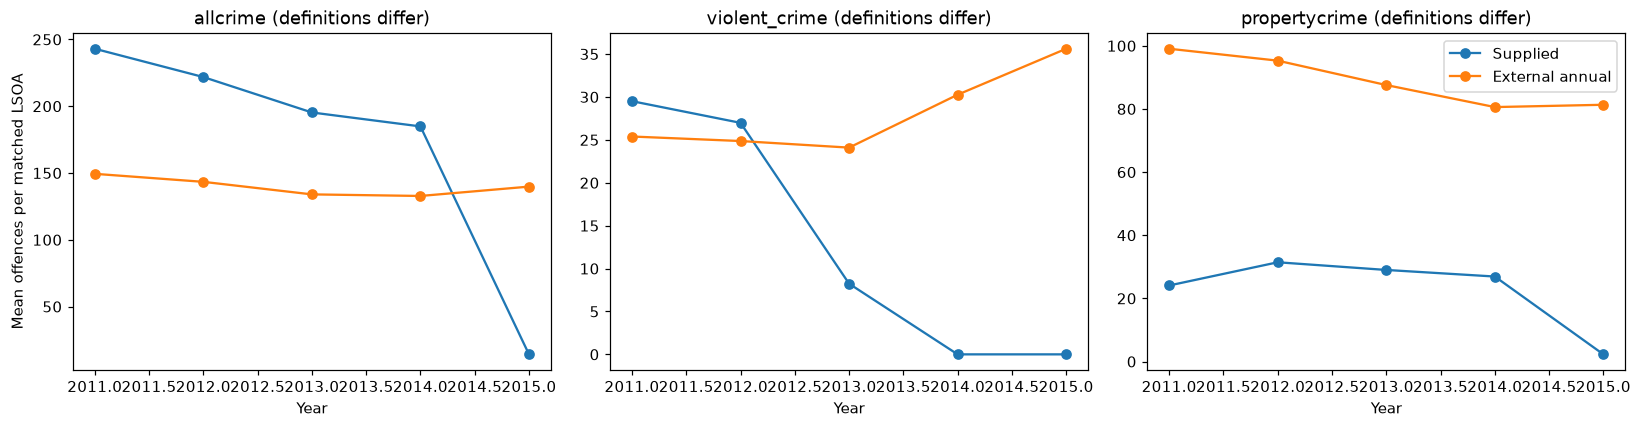

In [4]:
PAIRS={'allcrime':'mps_all','violent_crime':'mps_violence','propertycrime':'mps_property'}
area=merged.loc[merged.mps_geography_ok].groupby(['lsoacode','year'],as_index=False).first()
compare=[]
for supplied,ext in PAIRS.items():
    for year,b in area.groupby('year'):
        valid=b[[supplied,ext+'_annual']].dropna()
        compare.append({'supplied':supplied,'external':ext,'year':year,'lsoa_years':len(valid),
                        'supplied_mean':valid[supplied].mean(),'external_mean':valid[ext+'_annual'].mean(),
                        'supplied_zero_share':valid[supplied].eq(0).mean(),
                        'external_zero_share':valid[ext+'_annual'].eq(0).mean(),
                        'correlation':valid[supplied].corr(valid[ext+'_annual']) if valid[supplied].nunique()>1 and len(valid)>2 else np.nan,
                        'exact_match_share':valid[supplied].eq(valid[ext+'_annual']).mean()})
table(pd.DataFrame(compare),'supplied_vs_external_annual')
monthly_audit=monthly.reset_index()
monthly_audit['year']=monthly_audit.month.dt.year
supplied_area=df.groupby(['lsoacode','year'],as_index=False)[list(PAIRS)].first()
month_comparison=monthly_audit.merge(supplied_area,on=['lsoacode','year'],how='inner',validate='many_to_one')
diagnostic=[]
for month,b in month_comparison.groupby('month'):
    diagnostic.append({'month':str(month),'lsoas':len(b),
                       'allcrime_matches_month_share':b.allcrime.eq(b.mps_all).mean(),
                       'supplied_mean':b.allcrime.mean(),'monthly_mean':b.mps_all.mean()})
diagnostic=pd.DataFrame(diagnostic)
table(diagnostic,'supplied_allcrime_vs_individual_months')
table(diagnostic.assign(year=diagnostic.month.str[:4]).sort_values('allcrime_matches_month_share',ascending=False).groupby('year').head(1),
      'best_matching_month_per_year')
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(supplied,ext) in zip(axes,PAIRS.items()):
    b=pd.DataFrame(compare).loc[lambda x:x.supplied.eq(supplied) & x.lsoa_years.gt(0)]
    ax.plot(b.year,b.supplied_mean,'o-',label='Supplied')
    ax.plot(b.year,b.external_mean,'o-',label='External annual')
    ax.set_title(supplied+' (definitions differ)'); ax.set_xlabel('Year')
axes[0].set_ylabel('Mean offences per matched LSOA'); axes[-1].legend()
fig.tight_layout();fig.savefig(OUT/'crime_measurement_comparison.png',dpi=160);plt.show()

## 4. Exposure variation and a controlled annual-versus-prior comparison

Preferred comparisons use the external source for both annual and prior measures, holding crime definitions fixed. Annual crime includes future incidents relative to a sale; prior exposure excludes the sale month. Both use `log(1 + count)` to retain verified zeros. A coefficient describes a log-price association with log(1 + recorded offences), not exactly a crime elasticity.

M6 absorbs LSOA and year-quarter effects. M7 additionally absorbs borough-by-year effects and omits economic variables defined at borough-year level. Property, amenities and within-LSOA socioeconomic controls are retained when identified. Standard errors are clustered by LSOA. The implementation checks absorption convergence and drops collinear/absorbed controls. Cluster inference uses G/(G−1), t(G−1), and no additional correction for absorbed degrees of freedom; R² is within R².

Job density is excluded throughout this extension to retain 2015. All three main crime categories and both timings use exactly the same complete sample. LSOAs with inconsistent transaction borough assignments are excluded pending verification. These estimates remain vulnerable to local time-varying confounding and changes in the housing sold.

In [5]:
df=merged.copy()
CRIMES=['allcrime','violent_crime','propertycrime']
df['lnprice'] = np.log(df.price.where(df.price.gt(0)))
df['newbuild'] = df.age.eq('Y').astype(float)
df['borough_year'] = df.oslaua + '_' + df.year.astype(str)
for c in CRIMES:
    assert df[c].ge(0).all()
    df['log1p_'+c] = np.log1p(df[c])
for c in ['tube_distnear','bus_distnear','thamesriv_dist','Nearest_Park_dist']:
    df[c+'_km'] = df[c]/1000
df['lnpay'] = np.log(df.grossannualpay.where(df.grossannualpay.gt(0)))
PROPERTY = ['detached_dum','semi_d_dum','terrace_dum','freehold','newbuild']
AMENITY = ['tube_distnear_km','bus_distnear_km','thamesriv_dist_km','Nearest_Park_dist_km',
           'dist_to_cbd','Bus_stopscount_200m','heritage_count_200m']
SOCIAL = ['percent_noedu','percent_minorities','lone_hh']
ECONOMIC = ['lnpay','jobdensity','hoursworked','unemployment']


def absorb(matrix, groups, tol=1e-10, max_iter=2000):
    z = np.asarray(matrix, dtype=float).copy()
    codes = [pd.factorize(g, sort=False)[0] for g in groups]
    if any((g < 0).any() for g in codes): raise ValueError('Missing fixed-effect ID')
    for iteration in range(max_iter):
        before = z.copy()
        for g in codes:
            counts = np.bincount(g)
            sums = np.column_stack([np.bincount(g,weights=z[:,j],minlength=len(counts))
                                    for j in range(z.shape[1])])
            z -= (sums / counts[:,None])[g]
        if np.max(np.abs(z-before)) < tol:
            return z, iteration+1
    raise RuntimeError('Fixed-effect absorption did not converge')

def fit_absorbed(data, crime, controls, fixed_effects, cluster='lsoacode'):
    names = [crime] + controls
    x = data[names].to_numpy(dtype=float, copy=True)
    scale = x.std(axis=0)
    scale[scale < 1e-14] = 1
    x /= scale
    y = data.lnprice.to_numpy(float)
    if fixed_effects:
        z, iterations = absorb(np.column_stack([y,x]), [data[c] for c in fixed_effects])
        y, x = z[:,0], z[:,1:]
    else:
        y = y-y.mean(); x = x-x.mean(axis=0); iterations = 0
    # Select independent columns from the small Gram matrix, keeping crime first.
    gram = x.T @ x
    keep = []
    for j in range(x.shape[1]):
        residual_norm2 = gram[j,j]
        if keep:
            cross = gram[keep,j]
            residual_norm2 -= cross @ np.linalg.solve(gram[np.ix_(keep,keep)],cross)
        if residual_norm2 > 1e-10 * len(data): keep.append(j)
    if 0 not in keep: raise ValueError('Crime has no identifying variation in this specification')
    design = x[:,keep]
    beta = np.linalg.lstsq(design,y,rcond=None)[0]
    residual = y-design@beta
    group = pd.factorize(data[cluster],sort=False)[0]
    G = group.max()+1
    if G < 2: raise ValueError('Need multiple inference clusters')
    scores = np.zeros((G,len(keep)))
    for j in range(len(keep)):
        scores[:,j] = np.bincount(group,weights=design[:,j]*residual,minlength=G)
    bread = np.linalg.inv(design.T@design)
    covariance = bread @ (scores.T@scores) @ bread * G/(G-1)
    estimates = beta/scale[keep]
    se = np.sqrt(np.maximum(np.diag(covariance),0))/scale[keep]
    j = keep.index(0); critical = stats.t.ppf(.975,G-1)
    result = {'N':len(data),'clusters':G,'beta':estimates[j],'se':se[j],
              'p':2*stats.t.sf(abs(estimates[j]/se[j]),G-1),
              'ci_low':estimates[j]-critical*se[j], 'ci_high':estimates[j]+critical*se[j],
              'r2':1-residual@residual/(y@y),'r2_type':'within' if fixed_effects else 'ordinary',
              'crime_residual_sd':x[:,0].std()*scale[0], 'iterations':iterations,
              'absorbed_or_collinear':'; '.join(names[j] for j in range(len(names)) if j not in keep),
              'fixed_effects':'; '.join(fixed_effects)}
    coefficients = pd.DataFrame({'variable':[names[j] for j in keep], 'beta':estimates,'se':se})
    return result, coefficients

def specifications(include_jobdensity=True):
    economic = [c for c in ECONOMIC if include_jobdensity or c != 'jobdensity']
    p, a = PROPERTY, PROPERTY+AMENITY
    full = a+SOCIAL+economic
    return [('M1',[],[]),('M2',p,[]),('M3',a,[]),('M4',full,[]),
            ('M5',full,['msoa11','yearquarter']),('M6',full,['lsoacode','yearquarter']),
            ('M7',a+SOCIAL,['lsoacode','yearquarter','borough_year'])]

def common_sample(data, include_jobdensity=True, crime_cols=None):
    crime_cols = crime_cols or ['log1p_'+c for c in CRIMES]
    needed = set(['lnprice','lsoacode','msoa11','yearquarter','borough_year']+crime_cols)
    for _, controls, _ in specifications(include_jobdensity): needed.update(controls)
    valid = data[list(needed)].replace('',np.nan).notna().all(axis=1)
    valid &= np.isfinite(data[list(needed)].select_dtypes(include='number')).all(axis=1)
    # Restrict to London authorities, with explicit exclusion of eight border observations.
    valid &= data.oslaua.str.startswith('E090')
    london = data.loc[data.oslaua.str.startswith('E090')]
    borough_count = london.groupby('lsoacode').oslaua.nunique()
    ambiguous = borough_count.index[borough_count.gt(1)]
    valid &= ~data.lsoacode.isin(ambiguous)
    return data.loc[valid].copy()

Identical annual/prior regression sample: 405088 transactions; 4648 LSOAs
Estimating M6
Estimating M7


,N
year,
2011,66741
2012,85375
2013,99429
2014,108207
2015,45336


,count,mean,std,min,25%,50%,75%,max
log1p_mps_all_annual,405088.0,4.696446,0.663321,2.484907,4.276666,4.634729,5.036953,8.908154
log1p_mps_all_prior12,405088.0,4.701928,0.663372,2.302585,4.276666,4.644391,5.043425,8.915029
log1p_mps_violence_annual,405088.0,3.023905,0.759275,0.000000,2.564949,3.044522,3.526361,6.851185
log1p_mps_violence_prior12,405088.0,2.977324,0.759093,0.000000,2.484907,2.995732,3.465736,6.881411
log1p_mps_property_annual,405088.0,4.261834,0.670362,2.079442,3.828641,4.189655,4.584967,8.480529
log1p_mps_property_prior12,405088.0,4.284789,0.667584,1.791759,3.850148,4.219508,4.605170,8.493310


,model,measure,timing,N,clusters,beta,se,p,ci_low,ci_high,r2,r2_type,crime_residual_sd,iterations,absorbed_or_collinear,fixed_effects
0,M6,mps_all,annual,405088,4648,0.006813,0.004699,0.147162,-0.002399,0.016025,0.444375,within,0.138026,9,,lsoacode; yearquarter
1,M6,mps_all,prior12,405088,4648,-0.000426,0.005494,0.938210,-0.011196,0.010344,0.444370,within,0.136201,9,,lsoacode; yearquarter
2,M6,mps_violence,annual,405088,4648,-0.002266,0.002553,0.374757,-0.007271,0.002739,0.444372,within,0.256077,9,,lsoacode; yearquarter
3,M6,mps_violence,prior12,405088,4648,-0.003902,0.002676,0.144783,-0.009148,0.001343,0.444376,within,0.261906,9,,lsoacode; yearquarter
4,M6,mps_property,annual,405088,4648,0.010758,0.003952,0.006513,0.003010,0.018506,0.444388,within,0.165666,9,,lsoacode; yearquarter
5,M6,mps_property,prior12,405088,4648,0.004782,0.004315,0.267795,-0.003677,0.013242,0.444374,within,0.162395,9,,lsoacode; yearquarter
6,M7,mps_all,annual,405088,4648,0.010523,0.004366,0.015989,0.001963,0.019083,0.445742,within,0.133783,13,,lsoacode; yearquarter; borough_year
7,M7,mps_all,prior12,405088,4648,-0.000249,0.005176,0.961658,-0.010395,0.009898,0.445731,within,0.132582,13,,lsoacode; yearquarter; borough_year
8,M7,mps_violence,annual,405088,4648,0.001360,0.002405,0.571765,-0.003355,0.006075,0.445732,within,0.252522,13,,lsoacode; yearquarter; borough_year
9,M7,mps_violence,prior12,405088,4648,0.000006,0.002519,0.998019,-0.004932,0.004945,0.445731,within,0.258953,13,,lsoacode; yearquarter; borough_year


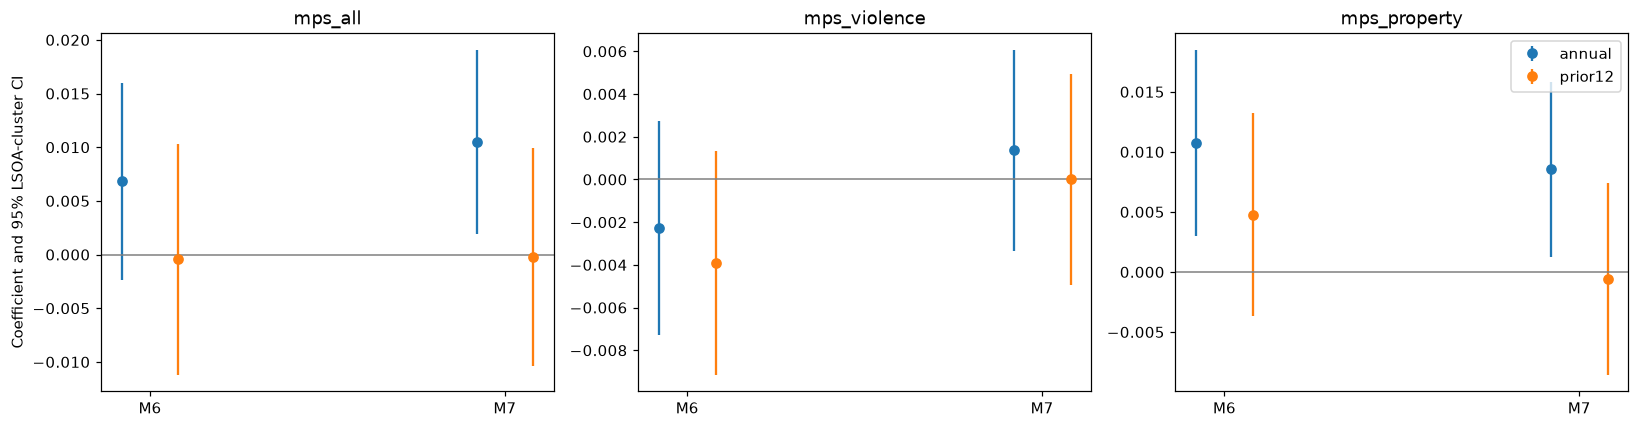

In [6]:
MAIN=['mps_all','mps_violence','mps_property']
timing_columns=[]
for c in MAIN:
    for timing in ['annual','prior12']:
        reg='log1p_'+c+'_'+timing
        df[reg]=np.log1p(df[c+'_'+timing])
        timing_columns.append(reg)
paired=common_sample(df,include_jobdensity=False,crime_cols=timing_columns)
assert paired.year.ge(2011).all()
assert paired.transactiondates.ge(pd.Timestamp('2011-04-01')).all()
print('Identical annual/prior regression sample:',len(paired),'transactions;',paired.lsoacode.nunique(),'LSOAs')
table(paired.groupby('year').size().to_frame('N'),'regression_sample_by_year')
table(paired[timing_columns].describe().T,'regression_crime_distributions')
results=[];coefficients=[]
for model,controls,effects in specifications(False)[-2:]:
    print('Estimating',model,flush=True)
    columns=['lnprice']+timing_columns+controls
    matrix=paired[columns].to_numpy(dtype=float,copy=True)
    scale=matrix.std(axis=0);scale[scale<1e-14]=1
    projected,iterations=absorb(matrix/scale,[paired[c] for c in effects])
    # Explicitly prevent numerical remnants of fully absorbed controls being rescaled.
    projected[:,projected.std(axis=0)<1e-7]=0
    transformed=paired.copy();transformed[columns]=projected*scale
    for measure in MAIN:
        for timing in ['annual','prior12']:
            reg='log1p_'+measure+'_'+timing
            r,b=fit_absorbed(transformed,reg,controls,[])
            r.update(fixed_effects='; '.join(effects),r2_type='within',iterations=iterations)
            results.append(dict(model=model,measure=measure,timing=timing,**r))
            coefficients.append(b.assign(model=model,measure=measure,timing=timing))
results=pd.DataFrame(results)
table(results,'external_timing_regressions')
pd.concat(coefficients).to_csv(OUT/'external_timing_all_coefficients.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,measure in zip(axes,MAIN):
    for timing,offset in [('annual',-.08),('prior12',.08)]:
        b=results.loc[results.measure.eq(measure)&results.timing.eq(timing)]
        ax.errorbar(np.arange(2)+offset,b.beta,yerr=np.vstack([b.beta-b.ci_low,b.ci_high-b.beta]),fmt='o',label=timing)
    ax.set_xticks([0,1],['M6','M7']);ax.set_title(measure);ax.axhline(0,color='grey',linewidth=1)
axes[0].set_ylabel('Coefficient and 95% LSOA-cluster CI');axes[-1].legend()
fig.tight_layout();fig.savefig(OUT/'annual_vs_prior12_coefficients.png',dpi=160);plt.show()

## 5. What can be used in the project?

**Recommended primary crime source:** the new monthly records provide explicit dates, nonzero violence measurements in 2014–2015 and complete 2011–2015 annual totals for matched LSOAs. Use their prior-twelve-month measures as the timing extension. The strongest annual comparison uses the same source, categories and transactions. Do not combine January–March 2010 missing months with later months as though they form a full annual total.

**Costs:** the first fifteen sale months lack sufficient prehistory; unmatched LSOAs, City of London and geography conflicts reduce coverage. Exact-code matching can select a subset of neighbourhoods, so assess the table below before generalising to London. Counts are not per-resident rates or land-area densities. The provided population and hectares variables are borough-level, so valid LSOA denominators are still needed for those normalisations.

**Remaining interpretation limits:** recorded categories may differ from the supplied measures; police reporting and classification changes can matter; buyers may negotiate before completion and may not observe all recorded incidents. A change in the coefficient is not proof that one model is causal. Residential burglary is available as a focused later extension but is not added to the main models here.

A significant annual estimate and an insignificant prior estimate do not, by themselves, establish a statistically significant difference between the two coefficients. That requires a joint test of their difference. Insignificance also does not establish that crime has no effect.

In [7]:
df['in_timing_sample']=df.transaction_id.isin(paired.transaction_id)
eligible=df.loc[df.transactiondates.ge(pd.Timestamp('2011-04-01')) & df.oslaua.str.startswith('E090')]
selection=eligible.groupby('in_timing_sample').agg(N=('price','size'),median_price=('price','median'),
    mean_price=('price','mean'),flat_share=('flat_dum','mean'),newbuild_share=('newbuild','mean'),
    lsoas=('lsoacode','nunique'))
table(selection,'included_vs_excluded_transactions')
preferred=results.loc[results.model.eq('M7') & results.timing.eq('prior12')]
table(preferred[['measure','N','clusters','beta','se','ci_low','ci_high','p','crime_residual_sd']],
      'preferred_prior12_summary')
print('M7 prior12 confidence intervals include zero:',
      dict(zip(preferred.measure,preferred.ci_low.le(0)&preferred.ci_high.ge(0))))
print('Main outputs are in',OUT)
print('Merged data: land_registry_crime_monthly_merged.csv.gz')
print('No original input file has been modified.')

Main outputs are in C:\Users\rachm\OneDrive - Nanyang Technological University\Syllabus\Y4S1\HE3027\project\monthly_crime_merge_outputs
Merged data: land_registry_crime_monthly_merged.csv.gz
No original input file has been modified.


,N,median_price,mean_price,flat_share,newbuild_share,lsoas
in_timing_sample,,,,,,
False,35418,312000.0,432725.723728,0.811565,0.393472,326
True,405088,333500.0,480617.063719,0.509452,0.064714,4648


Unnamed: 0,model,measure,timing,N,clusters,beta,se,p,ci_low,ci_high,r2,r2_type,crime_residual_sd,iterations,absorbed_or_collinear,fixed_effects
7,M7,mps_all,prior12,405088,4648,-0.000249,0.005176,0.961658,-0.010395,0.009898,0.445731,within,0.132582,13,NaN,lsoacode; yearquarter; borough_year
9,M7,mps_violence,prior12,405088,4648,0.000006,0.002519,0.998019,-0.004932,0.004945,0.445731,within,0.258953,13,NaN,lsoacode; yearquarter; borough_year
11,M7,mps_property,prior12,405088,4648,-0.000576,0.004073,0.887518,-0.008561,0.007409,0.445731,within,0.157253,13,NaN,lsoacode; yearquarter; borough_year


M7 prior12 confidence intervals include zero for all three crime measures.
